<a href="https://colab.research.google.com/github/id1557/deep-learning/blob/main/Tensorflow_Regresion_lineal_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#113D68" size=5>Redes neuronales y deep learning</font></h1>



<h1><font color="#113D68" size=6>Mi primera red neuronal con TensorFlow: <br>Regresión lineal</font></h1>


<br><br>
<div style="text-align: right">
<font size=3>Daniel González</font><br>
<font size=3>Semana 2: Frameworks de Deep Learning: TensorFlow</font><br>
<font size=3>IEBS</font>
</div>

---

<a id="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

* [Redes neuronales en Tensorflow](#section1)
    * [Regresión lineal](#section1.1)
    * [Preparar datos de entrenamiento](#section1.2)
    * [Construir la red](#section1.3)
    * [Configurar entrenamiento](#section1.4)
    * [Entrenar modelo](#section1.5)
    * [Evaluar modelo](#section1.5)
    * [Guardar y cargar un modelo](#section1.6)
    * [Predicciones](#section1.7)

In [1]:
import tensorflow as tf
import numpy as np

# Para mostrar gráficas
import matplotlib.pyplot as plt
%matplotlib inline

# Anaconda fixing problem
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

<a id="section1"></a>
# <font color="#004D7F" size=5>Redes neuronales en Tensorflow</font>
En este cuaderno veremos cómo crear nuestra primera red neuronal y cómo entrenarla en TensorFlow.

Los pasos comunes que se llevan acabo a la hora de entrenar una red neuronal son los siguientes:

- **Preparar datos de entrenamiento**: preparamos los datos con los que queremos entrenar nuestra red.
- **Construir la red**: construiremos la arquitectura de la red.
- **Configurar entrenamiento**: establecemos la configuración del entrenamiento como son las métricas a medir (error, precisión, etc.), el optimizador a utilizar, número de *epochs*, tamaño del *batch*, etc.
- **Entrenar modelo**: usaremos un conjunto de datos de entrada para entrenar nuestra red y obtener un modelo.
- **Evaluar modelo**: evaluamos el modelo resultante del entrenamiento para comprobar su correcto funcionamiento.
- **Guardar modelo**: guardamos el modelo para poder cargarlo después.

Empezaremos con un problema de regresión lineal para crear nuestra primera red neuronal con TensorFlow.

<a id="section1.1"></a>
# <font color="#004D7F" size=4>Regresión lineal</font>
Para crear nuestra primera red neuronal utilizaremos un problema de regresión lineal ya que es uno de los problemas más comunes para resolver usando redes neuronales. Como recordatorio, un poblema de regresión lineal está basado en la combinación de la entrada de datos, la salida, los pesos y los sesgos. Una operación lineal está dada por:

<h3 align="center">$y = xW + b$</h3>


Donde:

* **x** la entrada de datos.
* **y** la salida producida.
* **W** son los pesos.
* **b** son los segos.

>*Ejemplo:*
>
> En la siguiente imagen, podemos ver una representación de una red neuronal simple de tan solo una capa usando una función líneal básica. Esta red está definida por:
>
> * La entrada **x** con dimensión 10.
> * La salida **y** con dimensión 3.
> * Los pesos **W** con dimensión 10x3.
> * Los sesgos **b** con dimensión 3.
>
> A la izquierda tenemos la representación de la red por neurona y la derecha tenemos la misma red con una representación típica cuando trabajamos con redes neuronales profundas, ya que es una representación clara de las dimensiones de las matrices y vectores que se usan en la red.
>
> <div align="center"><img src="https://drive.google.com/uc?id=1jhPgeRF89dffvNlvZ8FeOjZmmwwl7r12" width="900"></div>


La primera red que creareamos tendrá la siguiente arquitectura:
- Una dimensión de entrada de tamaño 1.
- Una dimensión de salida de tamaño 1.
- Una neurona en las capas internas.

<div align="center"><img src="https://drive.google.com/uc?id=1QC7kFCgnNU41dB2OmXUGYDaEQumKJMWi" width="300"></div>

<a id="section1.2"></a>
# <font color="#004D7F" size=4>Preparar datos de entrenamiento</font>

Utilizaremos datos sintético de entrada `x` y datos de salida `y` de dimensión 1 y que sigan una distribución lineal para que sea sencillo visualizar cómo aprende nuestra red. Los generaremos aleatoriamente utilizando el método `np.linspace` añadiéndole ruido entre -1.5 y 1.5.

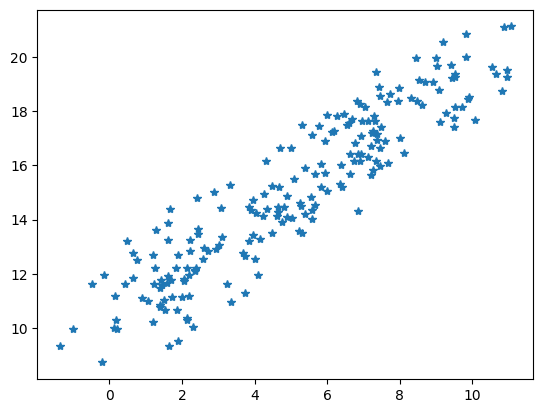

In [2]:
x_data = np.linspace(0,10,200) + np.random.uniform(-1.5,1.5,200)
y_data = np.linspace(10,20,200) + np.random.uniform(-1.5,1.5,200)
plt.plot(x_data,y_data,'*')

Como podemos ver, hemos generado 200 valores aleatorios que siguen una distribución lineal. El siguiente paso será dividir todos los datos en datos de entrenamiento para entrenar nuestra red y datos de test para evaluar el modelo conseguido.

In [3]:
# mezclamos los datos de forma aleatoria
indices = np.arange(x_data.shape[0])
np.random.shuffle(indices)
x_data = x_data[indices]
y_data = y_data[indices]

# dividimos 160 datos para el entrenamiento y 40 datos para el test
x_train = x_data[:160]
y_train = y_data[:160]
x_test = x_data[160:]
y_test = y_data[160:]

In [4]:
x_train

array([ 1.23250647,  2.20572604,  1.64346749,  2.2893446 ,  2.4100416 ,
        1.39275864,  2.04644192,  3.9646212 ,  5.93735179,  7.33987429,
        1.26359831,  6.77507234,  6.84210001,  4.14335021,  0.66062976,
        7.95777686,  2.04309294,  5.29307012,  0.90819159,  2.3673868 ,
       -1.35980854,  2.88443571,  1.21060959,  6.93781543,  5.00451669,
        9.52070568,  6.89171479,  2.92479903,  1.28280685,  5.21682111,
       10.82522101,  8.44036237,  4.66870804,  4.74206927,  6.44852062,
        4.82091531,  5.76232868,  2.12419598,  1.38204502,  9.41063007,
        6.26233058,  5.26196054,  8.68791874,  3.02343108,  2.45398167,
        5.08994091,  9.71793327,  2.42938917,  2.22665946,  3.90600273,
        9.4414591 , 10.94202526,  7.13065146,  3.84714926,  6.1403814 ,
        8.31633146,  1.06484509,  4.88917271, -0.14850924,  0.65951427,
        7.65848302,  1.53588986,  0.19330371,  6.53280586,  7.22255757,
        9.89192705,  1.45350203,  7.31315924,  3.72437548,  3.95

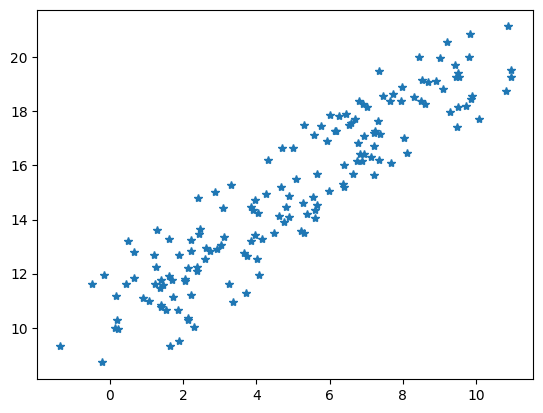

In [5]:
plt.plot(x_train,y_train,'*')

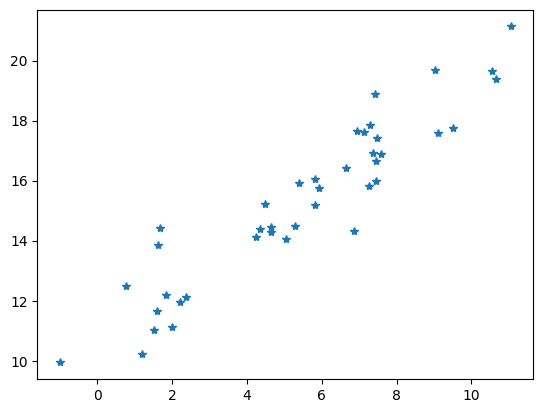

In [6]:
plt.plot(x_test,y_test,'*')


<a id="section1.4"></a>
# <font color="#004D7F" size=4>Construir la red</font>
Una vez tenemos los datos preparados, vamos a construir la red. Para construir la red utilizaremos el módulo de *Keras* (`tf.keras`), el cual nos facilita la creación de modelos en gran medida, ya que este módulo tiene varias capas pre-definidas que podemos usar.

Para crear un modelo podemos hacerlo de dos formas distintas:

- Crear un modelo `Sequential` donde le pasaremos la lista de capas en orden desde la entrada hasta la salida. **[Recomendada]**
- Creando un modelo `Sequential` y añadiendo cada capa una a una en orden.

Existen numerosas capas que podemos añadir, en nuestro caso usaremos la capa tipo `Dense`, que es la capa básica de una red neuronal vista en clase. La capa `Dense` tiene como parámetro principal el número de neuronas.

> **Nota**: podemos ver todas las capas que incluye TensorFlow en este link: https://www.tensorflow.org/api_docs/python/tf/keras/layers


In [7]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(1,)),
  tf.keras.layers.Dense(1),
])

# Alternativa:
# model = tf.keras.models.Sequential()
# model.add(tf.keras.layers.Dense(1, input_shape=(1,)))

Podemos ver un resumen de nuestra red la función `summary`.

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

De esta forma ya hemos creado nuestra red, es decir, hemos establecido cada capa, el tamaño de entrada y salida de los datos, y los pesos y sesgos (aleatorios).

Podemos ver los **pesos** y los **sesgos** creados de la siguiente forma:

In [9]:
model.weights

[<Variable path=sequential/dense/kernel, shape=(1, 1), dtype=float32, value=[[1.2835025]]>,
 <Variable path=sequential/dense/bias, shape=(1,), dtype=float32, value=[0.]>]

También podemos ver las **capas** de nuestra red:

In [10]:
model.layers

[<Dense name=dense, built=True>]

> **Nota**: una buena práctica es inicializar los pesos con valores aleatorios siguiendo una distribución normal, ya que de esta forma evitaremos que una red se estanque en un mínimo local mientras la entrenamos. También se pueden utilizar valores aleatorios sin seguir una distribución normal pero suele dar peores resultados.
>
> En cambio, los sesgos se suelen inicializar con el valor 0 ya que con la inicialización de los pesos ya evitamos estancarnos en mínimos locales.


<a id="section1.4"></a>
# <font color="#004D7F" size=4>Configurar el entrenamiento</font>
Una vez tenemos nuestra red creada y antes de entrenar, tenemos que configurar cómo queremos entrenar nuestra red. Tendremos que determinar la estrategia con la que entrenaremos nuestra red (optimizador), la función de coste o error que utilzaremos y las métricas que queremos evaluar durante el entrenamiento.

Para realizar esto, el modelo tiene una función llamada `compile` con la que poder establecer esta configuración. Esta función tiene 3 argumentos:

- `optimizer`: estrategia con la que entrenaremos nuestra red. Estas estrategias se llaman optimizadores y TensorFlow nos ofrece gran cantidad de ellos, la mayoría están basado en el gradiente descendiente. Podemos ver todos aquí: https://www.tensorflow.org/api_docs/python/tf/keras/optimizers
- `loss`: la función de cotes que usaremos para entrenar nuestra red. TensorFlow nos ofrece gran cantidad de funciones de coste dependiendo del problema que queramos resolver. Podemos ver todas aquí: https://www.tensorflow.org/api_docs/python/tf/keras/losses
- `metrics`: las métricas que queremos que se evalúen y se muestren durante el entrenamiento. Estas métricas dependerán de la función de coste que elijamos. Podemos ver todas las métricas que ofrece TensorFlow aquí: https://www.tensorflow.org/api_docs/python/tf/keras/metrics

En nuestra red, utilizaremos:

- `optimizer`: *Stochastic gradient descent* (SGD). Uno de los más comunes junto al optimizador `Adam`.
- `loss`: *Mean Squared Error*, error utilizado para problemas de regresión.
- `metrics`: al usar *Mean Squared Error* mediremos este error.

In [11]:
model.compile(optimizer='sgd',
              loss='mean_squared_error',
              metrics=['mean_squared_error'])

In [12]:
opt = tf.keras.optimizers.SGD(
    learning_rate=0.0001
)

model.compile(optimizer=opt,
              loss='mean_squared_error',
              metrics=['mean_squared_error'])

> **Nota**: los optimizadores, error y métricas se pueden definir con `strings`, pero también se pueden definir con objetos específicos de TensorFlow.

<a id="section1.4"></a>
# <font color="#004D7F" size=4>Entrenar modelo</font>
Para entrenar nuestro modelo tenemos que utilizar el método `fit` de un modelo. Esta función utilizará la configuración establecida con el método `compile` y hará atumáticamente el entrenamiento del modelo. Internamente realizará un bucle de entrenamiento realizando *forward* y *backward propagation* el número de veces que establezcamos.

La función `fit` tiene varios argumentos, los más importantes son los siguientes:
- `x`: lista con los datos de entrenamiento. Estos serán los datos de entrada de nuestra red.
- `y`: lista con los datos de salida de nuestra red.
- `batch_size`: para definir el tamaño del *batch* en aquellos casos en los que tenegamos muchos datos y tengamos que "*trocearlos*" para entrenar ya que no caben en memoria. Por ejemplo, cuando estemos entrenando con imágenes.
- `epochs`: número de veces que queremos entrenar nuestra red.
- `callbacks`: lista de *callbacks*, son métodos que podemos utilizar durante el entrenamiento, como por ejemplo guardar un modelo en cada *epoch* o guardar logs de los entrenamiento en archivos. Estos son todos los *callbacks* disponibles: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks.
- `validation_data`: datos de validación o test para evaluar el error y calcular las métricas durante el entrenamiento en cada *epoch*.
- `validation_split`: si no establecemos datos de validación o test podemos particionar el conjunto de entrenamiento estableciendo en este parámetro la proporción del conjunto de test entre 0 y 1, e.g: `0.2`
- `shuffle`: para mezclar y desordenar los datos.
- `verbose`: imprimir logs durante el entrenamiento. Por defecto está activado (1).

> **Nota**: Un *epoch* es cuando una red he utilizado todos los datos de entrenamiento. Normalmente una red no se entrena con un solo *epoch*, sino que se necesitan varios para que los pesos converjan.

> **Nota**: El uso de *batches* es una técnica para entrenar redes usando subconjunto de datos en lugar de todos los datos a la vez. Esta técnica permite entrenar modelos incluso si un ordenardor no es capaz de guardar en memoria todo el conjunto de datos.
>
>El uso de *batches* es computacionalmente ineficiente, ya que no podemos calcular el error del modelo simultánemante con todos los datos, pero es un pequeño precio a pagar para poder entrenar un modelo.

En nuestro entrenamiento usaremos `x`, `y`, `epochs` y `validation_data`:

In [13]:
hist = model.fit(x=x_train, y=y_train, epochs=100, validation_data=(x_test, y_test))

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 74.8719 - mean_squared_error: 74.8719 - val_loss: 68.3685 - val_mean_squared_error: 68.3685
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 71.7780 - mean_squared_error: 71.7780 - val_loss: 65.2867 - val_mean_squared_error: 65.2867
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 68.8890 - mean_squared_error: 68.8890 - val_loss: 62.4153 - val_mean_squared_error: 62.4153
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 66.1942 - mean_squared_error: 66.1942 - val_loss: 59.7457 - val_mean_squared_error: 59.7457
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 63.6783 - mean_squared_error: 63.6783 - val_loss: 57.2669 - val_mean_squared_error: 57.2669
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 61.3317 - mean_squared_error: 61.3317 - val_loss: 54.9592 - val_mean_squared_error: 54.9592
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 59.1433 - mean_squared_error: 59.1433 - va

Cuando entrenamos un modelo usando la función `fit`, esta nos devuelve un objeto `History` con todos los datos del entrenamiento. Por ejemplo, podemos ver los parámetros con los que hemos utilizado con el atributo `params` y ver el histórico del error de *train* y *validation* con el atributo `history`.

In [14]:
hist.params

{'verbose': 'auto', 'epochs': 100, 'steps': 5}

In [15]:
hist.history

{'loss': [74.87187957763672,
  71.77804565429688,
  68.88899993896484,
  66.1942367553711,
  63.67826461791992,
  61.331748962402344,
  59.143287658691406,
  57.097381591796875,
  55.191078186035156,
  53.411705017089844,
  51.75190353393555,
  50.20231246948242,
  48.75525665283203,
  47.40550231933594,
  46.14458465576172,
  44.9666748046875,
  43.866661071777344,
  42.84188461303711,
  41.883365631103516,
  40.9887809753418,
  40.15229034423828,
  39.37218475341797,
  38.64488983154297,
  37.96113967895508,
  37.32464599609375,
  36.730995178222656,
  36.17409133911133,
  35.655120849609375,
  35.170875549316406,
  34.718292236328125,
  34.294281005859375,
  33.89781951904297,
  33.52729415893555,
  33.18053436279297,
  32.85553741455078,
  32.5510139465332,
  32.26850509643555,
  32.000953674316406,
  31.75248146057129,
  31.52078628540039,
  31.300989151000977,
  31.096298217773438,
  30.906124114990234,
  30.724987030029297,
  30.55875587463379,
  30.401113510131836,
  30.2518577

Si comprobamos los pesos y sesgos del modelo, podremos ver cómo han cambiado:

In [16]:
model.weights

[<Variable path=sequential/dense/kernel, shape=(1, 1), dtype=float32, value=[[2.3623917]]>,
 <Variable path=sequential/dense/bias, shape=(1,), dtype=float32, value=[0.42769405]>]

Vamos a coger los valores del peso y el sesgo entrenados:

<h3 align="center">$y = xw + b$</h3>

In [17]:
weights = model.get_weights()
model_w = weights[0][0][0]
model_b = weights[1][0]
print(f'w: {model_w}')
print(f'b: {model_b}')

w: 2.362391710281372
b: 0.42769405245780945


<a id="section1.5"></a>
# <font color="#004D7F" size=4>Evaluar modelo</font>


Una vez que hemos entrenado nuestro modelo debemos evaluar el resultado obtenido. Para ello, los modelos tiene un método `evaluate` para evaluar el modelo. Este método utiliza hace predicciones de los datos que le pasamos y los compara con los resultados que deberían de dar.

Evaluemos el modelo con el conjunto de train y el conjunto de test:

In [18]:
print("Train score:", model.evaluate(x_train, y_train))
print("Test score:", model.evaluate(x_test, y_test))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 27.6834 - mean_squared_error: 27.6834 
Train score: [27.683414459228516, 27.683414459228516]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 25.3367 - mean_squared_error: 25.3367
Test score: [25.336734771728516, 25.336734771728516]


También podemos visualizar cómo ha sido el entrenamiento usando el histórico y viendo si el error ha ido descendiendo durante el entrenamiento:

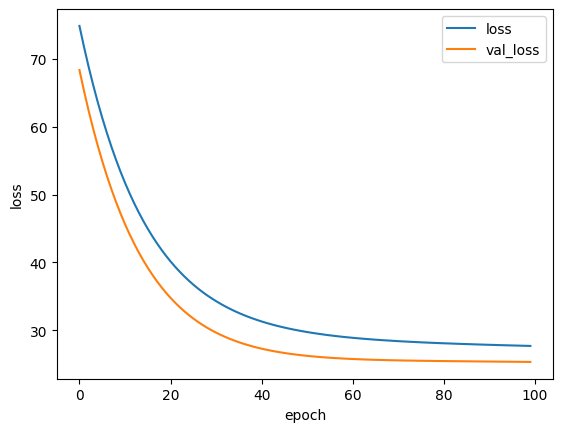

In [19]:
plt.plot(hist.history['loss'], label="loss")
plt.plot(hist.history['val_loss'], label="val_loss")
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend()

También podemos visualizar los valores de *w* y *b* que nuestra red ha aprendido para ver cómo se ajusta el modelo que hemos aprendido a los datos del problema.

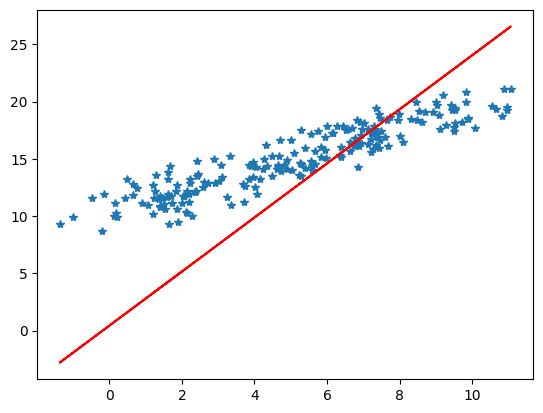

In [20]:
y_hat = x_data * model_w + model_b
plt.plot(x_data,y_data,'*')
plt.plot(x_data,y_hat,'r')
plt.show()

<a id="section1.6"></a>
# <font color="#004D7F" size=4>Guardar y cargar un modelo</font>
Una vez hemos entrenado y evaluado nuestro modelo y hemos visto que funciona como esperábamos, debemos de guardarlo para poder utilizarlo donde queramos. Para ello podemos utilizar el método `save` de un modelo indicandole el nombre con el que queremos guardarlo y el formato (*h5*).

In [21]:
model.save('my_model.h5')

Este modelo se guarda en la máquina virtual de Colab, cuando apaguemos la máquina lo perderemos por lo que debemos de descargarlo o guardarlo en Google Drive.

Para cargar un modelo directamente podemos hacerlo con el método `tf.keras.models.load_model(filepath)`, indicándole la ruta donde está nuetro modelo guardado.

In [22]:
model2 = tf.keras.models.load_model('my_model.h5')

Podemos comprobar que es el mismo modelo:

In [23]:
model2.layers

[<Dense name=dense, built=True>]

In [24]:
model2.weights

[<Variable path=sequential/dense/kernel, shape=(1, 1), dtype=float32, value=[[2.3623917]]>,
 <Variable path=sequential/dense/bias, shape=(1,), dtype=float32, value=[0.42769405]>]

<a id="section1.7"></a>
# <font color="#004D7F" size=4>Predicciones</font>
Una vez tenemos nuestro modelo entrenado y listo para usarse podemos realizar predicciones pasándole datos. Para ello podemos usar el método `predict` de un modelo.



In [29]:
import numpy as np
model.predict(np.array([1, 2, 3, 4, 10]).reshape(-1, 1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


array([[ 2.7900858],
       [ 5.1524773],
       [ 7.514869 ],
       [ 9.877261 ],
       [24.05161  ]], dtype=float32)

In [32]:
import numpy as np
# Usando reshape para asegurar que sea bidimensional (1, 1)
model.predict(np.array([100]).reshape(-1, 1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


array([[236.66685]], dtype=float32)